# Which orders are at risk of delay?

I use a decision tree to predict whether a simulated order will arrive late. This example adapts a classroom exercise and compares an unrestricted tree with a tree tuned by cross-validation and a majority-class baseline.

Open this notebook in VS Code with the Jupyter extension, select the virtual environment described in the README, and run all cells. The notebook generates the demonstration data with a fixed random seed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, balanced_accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

rng = np.random.default_rng(42)
n = 1600
orders = pd.DataFrame({
    "distance_km": rng.uniform(2, 100, n),
    "queue_size": rng.integers(0, 25, n),
    "rain": rng.binomial(1, 0.25, n),
    "weekend": rng.binomial(1, 0.30, n),
})
log_odds = (
    -2.8 + 1.7 * (orders["queue_size"] > 15)
    + 1.8 * ((orders["distance_km"] > 55) & (orders["rain"] == 1))
    + 1.0 * ((orders["distance_km"] > 70) & (orders["queue_size"] > 10))
    + 0.5 * orders["weekend"]
)
delayed = rng.binomial(1, 1 / (1 + np.exp(-log_odds)))
X_train, X_test, y_train, y_test = train_test_split(
    orders, delayed, test_size=0.25, stratify=delayed, random_state=42
)
print(f"Simulated orders: {n} | Share of delayed orders: {delayed.mean():.1%}")

Simulated orders: 1600 | Share of delayed orders: 20.2%


## Tuning the decision tree

The simulation includes interactions among rain, distance, and queue size. Stratified cross-validation on the training split selects tree depth, minimum leaf size, and the split criterion. Balanced accuracy gives equal weight to recall for delayed and on-time deliveries.

In [2]:
search = GridSearchCV(
    DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    {"max_depth": [2, 3, 4, 6], "min_samples_leaf": [15, 35, 60],
     "criterion": ["gini", "entropy"]},
    scoring="balanced_accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
).fit(X_train, y_train)
tree = search.best_estimator_
models = {
    "Majority-class baseline": DummyClassifier(strategy="most_frequent").fit(X_train, y_train),
    "Unrestricted tree": DecisionTreeClassifier(
        random_state=42, class_weight="balanced"
    ).fit(X_train, y_train),
    "Tuned tree": tree,
}

print("Best parameters:", search.best_params_)
scores = {}
for name, model in models.items():
    predicted = model.predict(X_test)
    scores[name] = {
        "Balanced accuracy": balanced_accuracy_score(y_test, predicted),
        "Delay F1": f1_score(y_test, predicted, zero_division=0),
    }
print(pd.DataFrame(scores).T.round(3).to_string())

Best parameters: {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 60}
                         Balanced accuracy  Delay F1
Majority-class baseline              0.500     0.000
Unrestricted tree                    0.625     0.403
Tuned tree                           0.703     0.495


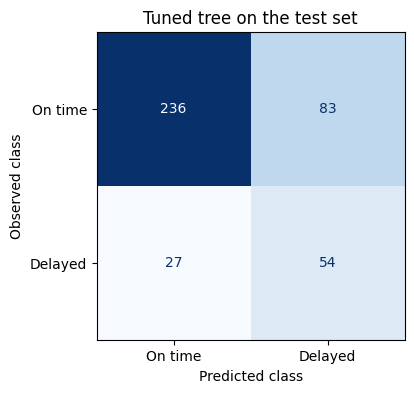

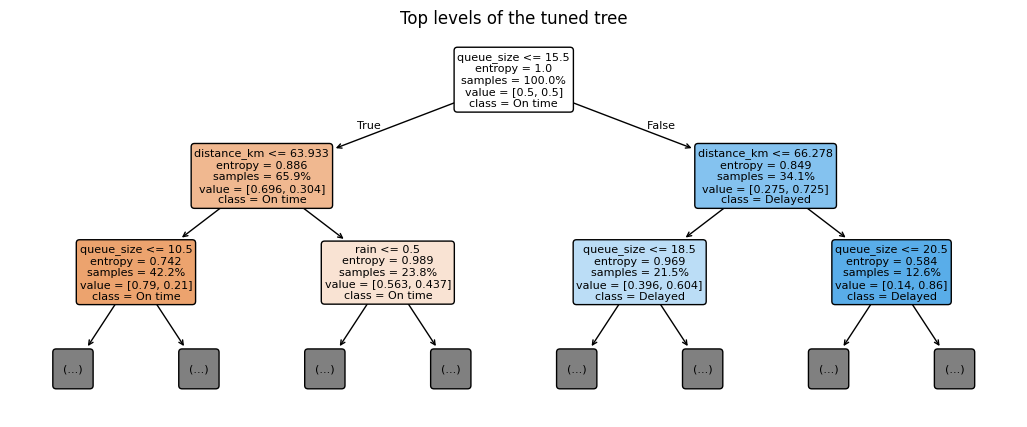

In [3]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(
    tree, X_test, y_test, display_labels=["On time", "Delayed"],
    cmap="Blues", colorbar=False, ax=ax
)
ax.set(title="Tuned tree on the test set", xlabel="Predicted class", ylabel="Observed class")
plt.show()

fig, ax = plt.subplots(figsize=(13, 5))
plot_tree(
    tree, feature_names=list(orders.columns), class_names=["On time", "Delayed"],
    max_depth=2, filled=True, rounded=True, proportion=True, fontsize=8, ax=ax
)
ax.set_title("Top levels of the tuned tree")
plt.show()

## Results

The tuned tree achieved a balanced accuracy of 0.703, compared with 0.625 for the unrestricted tree and 0.500 for the majority-class baseline. The confusion matrix shows missed delays and on-time orders flagged for review. These results depend on how the orders were simulated.